# Entregable 6 – Transformación Avanzada de Variables

**Asignatura:** Procesamiento de datos  
**Autora:** Taisiia Bogatyreva

## Objetivo
1. Generar un set de datos sintéticos con variables en distintas escalas, una variable asimétrica y variables categóricas.
2. Aplicar y comparar transformaciones: escalado (Min-Max, estandarización), codificación (One-Hot, ordinal) y *power transforms* (log, Yeo-Johnson).
3. Analizar histogramas antes/después y el impacto potencial en modelos (KNN y PCA).

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import (MinMaxScaler, StandardScaler, PowerTransformer,
                                   OneHotEncoder, OrdinalEncoder)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, f1_score

np.random.seed(42)   # reproducibilidad

## 1. Generación de datos sintéticos

Simularemos **1000 clientes** con estas variables:

| Variable | Tipo | Cómo generarla |
|---|---|---|
| `edad` | numérica (18–69) | `np.random.randint` |
| `ingreso` | numérica, **muy asimétrica** | `np.random.lognormal(mean=10.5, sigma=0.7, size=n)` |
| `antiguedad_meses` | numérica (1–240) | `np.random.randint` |
| `ciudad` | categórica **nominal** (sin orden) | `np.random.choice([...], p=[...])` |
| `nivel_educativo` | categórica **ordinal** | `np.random.choice(['primario','secundario','universitario'], ...)` |
| `compra` | objetivo binario (0/1) | probabilidad que depende de edad, antigüedad y nivel educativo |

> **Tu tarea:** genera las 5 variables de entrada y crea `df`.  
> *Pista:* el ingreso queda en decenas de miles y la edad en decenas: **esa diferencia de escala es justamente lo que queremos estudiar**.

In [29]:
# TODO: generar edad, ingreso, antiguedad_meses, ciudad, nivel_educativo
n = 1000

edad = np.random.randint(18, 70, size=n)
ingreso = np.random.lognormal(mean=10.5, sigma=0.7, size=n).round(0)
antiguedad_meses = np.random.randint(1, 241, size=n)

ciudad = np.random.choice(['Córdoba', 'Buenos Aires', 'Rosario', 'Mendoza'],
                          size=n, p=[0.3, 0.35, 0.2, 0.15])
nivel_educativo = np.random.choice(['primario', 'secundario', 'universitario'],
                                   size=n, p=[0.2, 0.5, 0.3])

> **Tu tarea:** genera la variable objetivo `compra`.  
> *Pista:* calcula un `score` lineal (por ejemplo `0.06*(edad-44) + 0.012*(antiguedad_meses-120) + 0.5*(nivel_num-1) + ruido`), conviértelo en probabilidad con la función sigmoide `1/(1+np.exp(-score))` y sortea con `np.random.binomial(1, prob)`.  
> Nota: el **ingreso no interviene** en `compra`; así veremos si un modelo se distrae por su escala.

In [30]:
# TODO: generar compra y armar df
# Числовой код уровня образования нужен только для расчёта score
nivel_num = pd.Series(nivel_educativo).map(
    {'primario': 0, 'secundario': 1, 'universitario': 2}
).values

score = (0.06 * (edad - 44)
         + 0.012 * (antiguedad_meses - 120)
         + 0.5 * (nivel_num - 1)
         + np.random.normal(0, 0.5, size=n))

prob = 1 / (1 + np.exp(-score))          # сигмоида: score → вероятность от 0 до 1
compra = np.random.binomial(1, prob)     # «подбрасываем монетку» с вероятностью prob

df = pd.DataFrame({
    'edad': edad,
    'ingreso': ingreso,
    'antiguedad_meses': antiguedad_meses,
    'ciudad': ciudad,
    'nivel_educativo': nivel_educativo,
    'compra': compra
})

> Inspecciona con `df.head()`, `df.describe()`, `df.dtypes` y `df['compra'].mean()`.

In [31]:
# TODO: inspección inicial
print(df.head())
print(df.dtypes)
print("Доля покупок:", df['compra'].mean())
df.describe().round(1)

   edad  ingreso  antiguedad_meses        ciudad nivel_educativo  compra
0    56  11796.0               101       Rosario      secundario       0
1    69  41874.0               186  Buenos Aires      secundario       1
2    46  21387.0               132       Rosario   universitario       0
3    32  13419.0               111       Rosario      secundario       1
4    60  23096.0               125       Córdoba   universitario       1
edad                  int64
ingreso             float64
antiguedad_meses      int64
ciudad                  str
nivel_educativo         str
compra                int64
dtype: object
Доля покупок: 0.535


,edad,ingreso,antiguedad_meses,compra
count,1000.0,1000.0,1000.0,1000.0
mean,43.8,47970.8,120.2,0.5
std,15.0,36313.5,66.7,0.5
min,18.0,4782.0,1.0,0.0
25%,31.0,23663.8,63.0,0.0
50%,44.0,37710.0,122.0,1.0
75%,56.0,58679.2,175.0,1.0
max,69.0,229273.0,240.0,1.0


## 2. Análisis exploratorio: escalas y asimetría

> **Tu tarea:** dibuja los histogramas de `edad`, `ingreso` y `antiguedad_meses` (uno al lado del otro) y calcula la asimetría (`skew()`) de cada una.  
> *Pista:* `fig, axes = plt.subplots(1, 3, figsize=(15, 4))` y `sns.histplot(df[col], ax=axes[i])`.

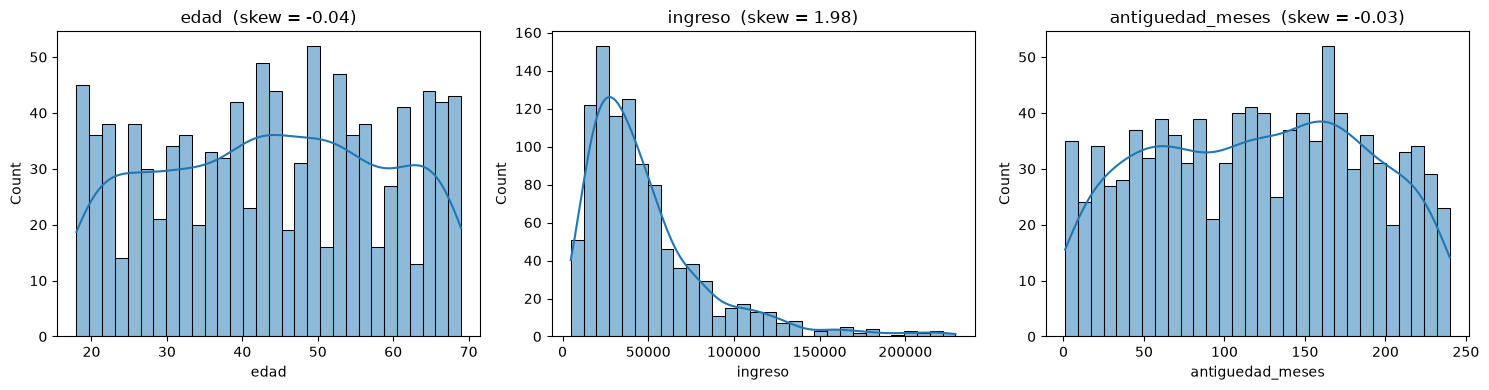

,edad,ingreso,antiguedad_meses
min,18.0,4782.0,1.0
max,69.0,229273.0,240.0
mean,43.8,47970.8,120.2
median,44.0,37710.0,122.0
std,15.0,36313.5,66.7
rango,51.0,224491.0,239.0


In [32]:
# TODO: histogramas + skew
cols_num = ['edad', 'ingreso', 'antiguedad_meses']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, cols_num):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title(f'{col}  (skew = {df[col].skew():.2f})')

plt.tight_layout()
plt.show()

# Сводка: масштабы признаков
resumen = df[cols_num].agg(['min', 'max', 'mean', 'median', 'std']).round(1)
resumen.loc['rango'] = resumen.loc['max'] - resumen.loc['min']
resumen

## 3. División Train / Test (ANTES de transformar)

> **Tu tarea:** separa `X` (todas menos `compra`) e `y`, y divide con `train_test_split(..., test_size=0.2, random_state=42, stratify=y)`.  
> **Regla de oro:** ningún `fit` sobre el conjunto de prueba (evita *data leakage*).

In [33]:
# TODO: X, y, X_train, X_test, y_train, y_test
X = df.drop(columns='compra')    # признаки: всё, кроме целевой переменной
y = df['compra']                 # целевая переменная

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Размеры X_train / X_test:", X_train.shape, X_test.shape)
print("Доля покупок в train:", round(y_train.mean(), 3))
print("Доля покупок в test: ", round(y_test.mean(), 3))

# Статистики двух выборок немного различаются
print("Среднее ingreso в train:", round(X_train['ingreso'].mean()))
print("Среднее ingreso в test: ", round(X_test['ingreso'].mean()))

Размеры X_train / X_test: (800, 5) (200, 5)
Доля покупок в train: 0.535
Доля покупок в test:  0.535
Среднее ingreso в train: 47339
Среднее ingreso в test:  50500


## 4. Escalado: Min-Max vs. Estandarización

> **Tu tarea:** ajusta (`fit`) `MinMaxScaler` y `StandardScaler` **solo con `X_train`** sobre las columnas numéricas y transforma ambos conjuntos.  
> *Pista:* `scaler.fit_transform(X_train[cols])` y `scaler.transform(X_test[cols])`.  
> Luego compara con histogramas el `ingreso` original, escalado Min-Max y estandarizado. ¿Qué cambia en la **forma** y en la **escala**?

### 4.1 Escalado (fit solo on train)

In [34]:
cols_num = ['edad', 'ingreso', 'antiguedad_meses']

minmax = MinMaxScaler()
std = StandardScaler()

# Min-Max: учимся на train, применяем к train и test
X_train_mm = pd.DataFrame(minmax.fit_transform(X_train[cols_num]),
                          columns=cols_num, index=X_train.index)
X_test_mm = pd.DataFrame(minmax.transform(X_test[cols_num]),
                         columns=cols_num, index=X_test.index)

# Стандартизация: то же самое
X_train_std = pd.DataFrame(std.fit_transform(X_train[cols_num]),
                           columns=cols_num, index=X_train.index)
X_test_std = pd.DataFrame(std.transform(X_test[cols_num]),
                          columns=cols_num, index=X_test.index)

print("Min-Max: min и max")
print(pd.DataFrame({
    'train_min': X_train_mm.min(), 'train_max': X_train_mm.max(),
    'test_min': X_test_mm.min(), 'test_max': X_test_mm.max()
}).round(3))

print("\nСтандартизация: среднее и σ")
print(pd.DataFrame({
    'train_mean': X_train_std.mean(), 'train_std': X_train_std.std(ddof=0),
    'test_mean': X_test_std.mean(), 'test_std': X_test_std.std(ddof=0)
}).round(3))

Min-Max: min и max
                  train_min  train_max  test_min  test_max
edad                    0.0        1.0     0.000     1.000
ingreso                 0.0        1.0    -0.001     0.927
antiguedad_meses        0.0        1.0     0.008     1.000

Стандартизация: среднее и σ
                  train_mean  train_std  test_mean  test_std
edad                    -0.0        1.0      0.010     0.925
ingreso                  0.0        1.0      0.090     1.139
antiguedad_meses        -0.0        1.0      0.024     1.004



### 4.2 Cómo ha cambiado el forma ingreso

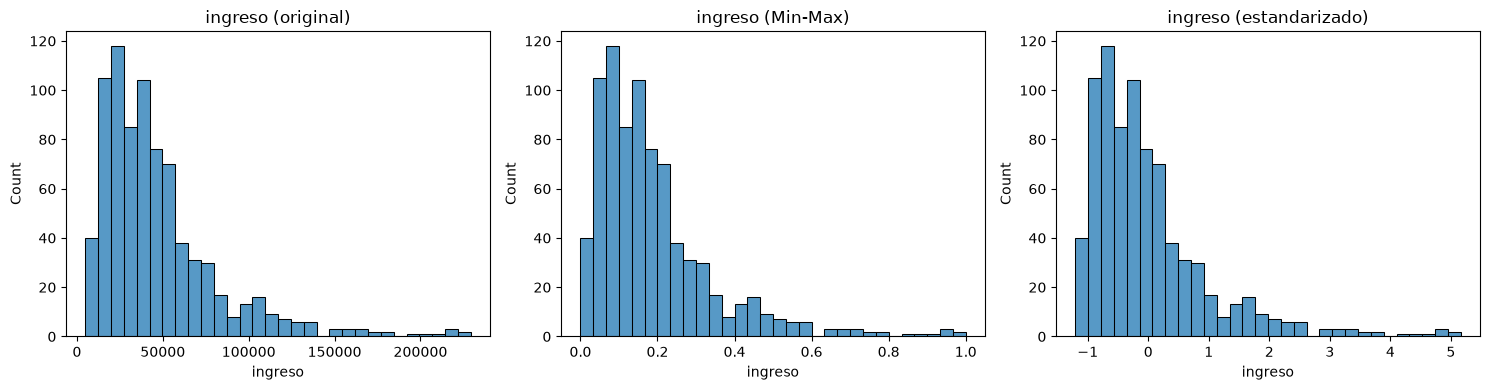

Асимметрия original: 2.04
Асимметрия Min-Max:  2.04
Асимметрия estandar: 2.04


count    800.000
mean       0.189
std        0.157
min        0.000
25%        0.083
50%        0.147
75%        0.234
max        1.000
Name: ingreso, dtype: float64

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(X_train['ingreso'], bins=30, ax=axes[0])
axes[0].set_title('ingreso (original)')

sns.histplot(X_train_mm['ingreso'], bins=30, ax=axes[1])
axes[1].set_title('ingreso (Min-Max)')

sns.histplot(X_train_std['ingreso'], bins=30, ax=axes[2])
axes[2].set_title('ingreso (estandarizado)')

plt.tight_layout()
plt.show()

print("Асимметрия original:", round(X_train['ingreso'].skew(), 2))
print("Асимметрия Min-Max: ", round(X_train_mm['ingreso'].skew(), 2))
print("Асимметрия estandar:", round(X_train_std['ingreso'].skew(), 2))

X_train_mm['ingreso'].describe().round(3)

## 5. Codificación de variables categóricas

> **Tu tarea:**
> - `ciudad` (nominal): One-Hot con `OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)`.
> - `nivel_educativo` (ordinal): `OrdinalEncoder(categories=[['primario', 'secundario', 'universitario']])`.
>
> Muestra el resultado como `DataFrame` (`encoder.get_feature_names_out()`).  
> Explica por qué **no** usar Label Encoding en `ciudad`.

### 5.1. One-Hot para ciudad

In [36]:
ohe = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)

cols_ciudad = ohe.fit(X_train[['ciudad']]).get_feature_names_out(['ciudad'])

ciudad_train = pd.DataFrame(ohe.transform(X_train[['ciudad']]),
                            columns=cols_ciudad, index=X_train.index)
ciudad_test = pd.DataFrame(ohe.transform(X_test[['ciudad']]),
                           columns=cols_ciudad, index=X_test.index)

print("Категории:", ohe.categories_)
print(pd.concat([X_train[['ciudad']], ciudad_train], axis=1).head())
print("Размеры:", ciudad_train.shape, ciudad_test.shape)

# Сумма по строке: у какой доли клиентов все нули?
print(ciudad_train.sum(axis=1).value_counts())

Категории: [array(['Buenos Aires', 'Córdoba', 'Mendoza', 'Rosario'], dtype=object)]
           ciudad  ciudad_Córdoba  ciudad_Mendoza  ciudad_Rosario
869       Mendoza             0.0             1.0             0.0
281       Córdoba             1.0             0.0             0.0
854  Buenos Aires             0.0             0.0             0.0
579       Rosario             0.0             0.0             1.0
154       Córdoba             1.0             0.0             0.0
Размеры: (800, 3) (200, 3)
1.0    507
0.0    293
Name: count, dtype: int64


### 5.2. Ordinal-codificación para nivel_educativo

In [37]:
orden = ['primario', 'secundario', 'universitario']
ord_enc = OrdinalEncoder(categories=[orden])

nivel_train = pd.DataFrame(ord_enc.fit_transform(X_train[['nivel_educativo']]),
                           columns=['nivel_educativo_ord'], index=X_train.index)
nivel_test = pd.DataFrame(ord_enc.transform(X_test[['nivel_educativo']]),
                          columns=['nivel_educativo_ord'], index=X_test.index)

print(pd.concat([X_train[['nivel_educativo']], nivel_train], axis=1).head())
print(nivel_train['nivel_educativo_ord'].value_counts().sort_index())

    nivel_educativo  nivel_educativo_ord
869      secundario                  1.0
281      secundario                  1.0
854   universitario                  2.0
579   universitario                  2.0
154   universitario                  2.0
nivel_educativo_ord
0.0    171
1.0    406
2.0    223
Name: count, dtype: int64


## 6. Power transforms para la asimetría

> **Tu tarea:** transforma `ingreso` con `np.log1p` y con `PowerTransformer(method='yeo-johnson')` (ajustado en train). Compara los tres histogramas (original, log, Yeo-Johnson) y los `skew()`.

### 6.1. log1p и Yeo-Johnson

In [38]:
# Логарифм: простая формула, ничего «изучать» по данным не нужно
ingreso_train_log = np.log1p(X_train['ingreso'])
ingreso_test_log = np.log1p(X_test['ingreso'])

# Yeo-Johnson: подбирает параметр λ по train
pt = PowerTransformer(method='yeo-johnson')
ingreso_train_yj = pd.Series(pt.fit_transform(X_train[['ingreso']]).ravel(),
                             index=X_train.index)
ingreso_test_yj = pd.Series(pt.transform(X_test[['ingreso']]).ravel(),
                            index=X_test.index)

print("λ (lambda), подобранная по train:", pt.lambdas_)

resumen_pt = pd.DataFrame({
    'original': X_train['ingreso'],
    'log1p': ingreso_train_log,
    'yeo_johnson': ingreso_train_yj
}).agg(['skew', 'mean', 'std', 'min', 'max']).round(2)
resumen_pt

λ (lambda), подобранная по train: [-0.01113779]


,original,log1p,yeo_johnson
skew,2.04,0.02,0.00
mean,47338.54,10.54,-0.00
std,35262.69,0.68,1.00
min,4944.00,8.51,-3.02
max,229273.00,12.34,2.64


### 6.2 Histogramas

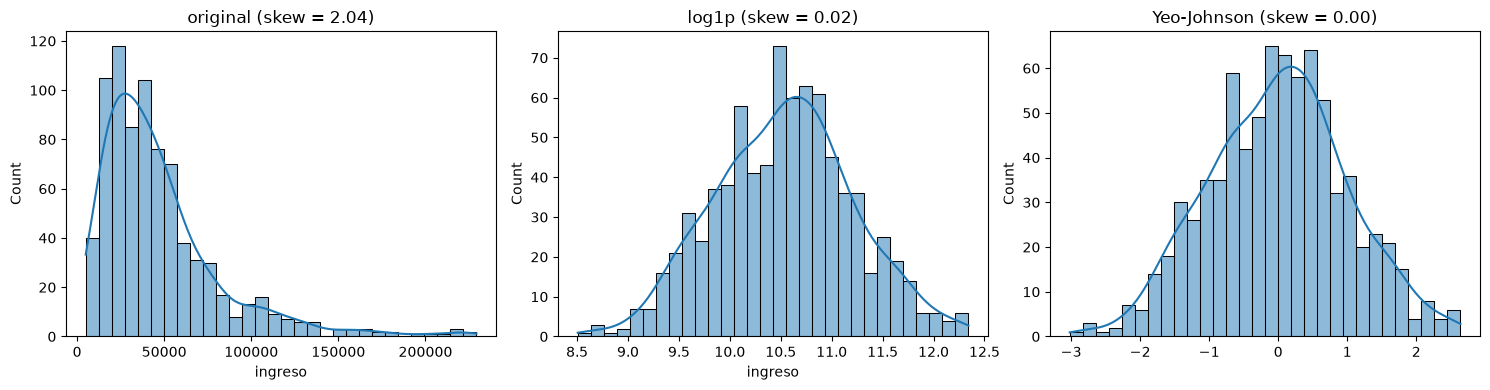

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(X_train['ingreso'], bins=30, kde=True, ax=axes[0])
axes[0].set_title(f"original (skew = {X_train['ingreso'].skew():.2f})")

sns.histplot(ingreso_train_log, bins=30, kde=True, ax=axes[1])
axes[1].set_title(f"log1p (skew = {ingreso_train_log.skew():.2f})")

sns.histplot(ingreso_train_yj, bins=30, kde=True, ax=axes[2])
axes[2].set_title(f"Yeo-Johnson (skew = {ingreso_train_yj.skew():.2f})")

plt.tight_layout()
plt.show()

## 7. Pipeline + ColumnTransformer

> **Tu tarea:** integra todo en un `ColumnTransformer`:
> - numéricas → `StandardScaler`
> - `ciudad` → `OneHotEncoder(drop='first', handle_unknown='ignore')`
> - `nivel_educativo` → `OrdinalEncoder(categories=[[...]])`
>
> Aplica `fit_transform` en train y `transform` en test.

In [40]:
orden = ['primario', 'secundario', 'universitario']

preprocesador = ColumnTransformer(transformers=[
    ('ingreso_yj', PowerTransformer(method='yeo-johnson'), ['ingreso']),
    ('num_std', StandardScaler(), ['edad', 'antiguedad_meses']),
    ('ciudad_ohe', OneHotEncoder(drop='first', handle_unknown='ignore',
                                 sparse_output=False), ['ciudad']),
    ('nivel_ord', OrdinalEncoder(categories=[orden]), ['nivel_educativo']),
])

X_train_prep = preprocesador.fit_transform(X_train)   # учимся на train
X_test_prep = preprocesador.transform(X_test)         # применяем к test

nombres = preprocesador.get_feature_names_out()
X_train_prep = pd.DataFrame(X_train_prep, columns=nombres, index=X_train.index)
X_test_prep = pd.DataFrame(X_test_prep, columns=nombres, index=X_test.index)

print(list(nombres))
print("Размеры:", X_train_prep.shape, X_test_prep.shape)
X_train_prep.head()

['ingreso_yj__ingreso', 'num_std__edad', 'num_std__antiguedad_meses', 'ciudad_ohe__ciudad_Córdoba', 'ciudad_ohe__ciudad_Mendoza', 'ciudad_ohe__ciudad_Rosario', 'nivel_ord__nivel_educativo']
Размеры: (800, 7) (200, 7)


,ingreso_yj__ingreso,num_std__edad,num_std__antiguedad_meses,ciudad_ohe__ciudad_Córdoba,ciudad_ohe__ciudad_Mendoza,ciudad_ohe__ciudad_Rosario,nivel_ord__nivel_educativo
869,-1.920723,-0.643681,-0.013517,0.0,1.0,0.0,1.0
281,-0.147466,-0.117556,-1.230060,1.0,0.0,0.0,1.0
854,-0.682776,0.474335,-1.064851,0.0,0.0,0.0,2.0
579,-3.020416,1.592351,-1.665613,0.0,0.0,1.0,2.0
154,0.798355,1.000460,1.458350,1.0,0.0,0.0,2.0


In [41]:
# Проверка: у train среднее 0 и σ 1 для числовых, у test немного иначе
pd.DataFrame({
    'train_mean': X_train_prep.mean(), 'train_std': X_train_prep.std(ddof=0),
    'test_mean': X_test_prep.mean(), 'test_std': X_test_prep.std(ddof=0)
}).round(2)

,train_mean,train_std,test_mean,test_std
ingreso_yj__ingreso,-0.00,1.00,0.04,1.09
num_std__edad,-0.00,1.00,0.01,0.92
num_std__antiguedad_meses,-0.00,1.00,0.02,1.00
ciudad_ohe__ciudad_Córdoba,0.26,0.44,0.27,0.44
ciudad_ohe__ciudad_Mendoza,0.15,0.36,0.14,0.35
ciudad_ohe__ciudad_Rosario,0.22,0.42,0.22,0.41
nivel_ord__nivel_educativo,1.06,0.70,1.12,0.72


## 8. Impacto en modelos

### 8.1 KNN con y sin escalado
> **Tu tarea:** entrena `KNeighborsClassifier(n_neighbors=5)` con **solo las columnas numéricas** en tres escenarios: (a) sin escalar, (b) con `StandardScaler`, (c) con `MinMaxScaler`. Usa `Pipeline`. Compara `accuracy` y `F1` en test.

In [42]:
cols_num = ['edad', 'ingreso', 'antiguedad_meses']

modelos = {
    'KNN sin escalar': Pipeline([
        ('knn', KNeighborsClassifier(n_neighbors=5))]),
    'KNN + StandardScaler': Pipeline([
        ('esc', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=5))]),
    'KNN + MinMaxScaler': Pipeline([
        ('esc', MinMaxScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=5))]),
}

resultados_knn = []

for nombre, modelo in modelos.items():
    modelo.fit(X_train[cols_num], y_train)
    pred = modelo.predict(X_test[cols_num])
    cv = cross_val_score(modelo, X[cols_num], y, cv=5, scoring='accuracy').mean()
    resultados_knn.append({
        'modelo': nombre,
        'accuracy': round(accuracy_score(y_test, pred), 3),
        'F1': round(f1_score(y_test, pred), 3),
        'accuracy_cv5': round(cv, 3)
    })

print(pd.DataFrame(resultados_knn))
print("Базовый уровень (всегда отвечать самым частым классом):",
      round(max(y_test.mean(), 1 - y_test.mean()), 3))

                 modelo  accuracy     F1  accuracy_cv5
0       KNN sin escalar     0.480  0.563         0.479
1  KNN + StandardScaler     0.635  0.670         0.657
2    KNN + MinMaxScaler     0.585  0.614         0.664
Базовый уровень (всегда отвечать самым частым классом): 0.535


### 8.2 PCA con y sin estandarizar
> **Tu tarea:** ajusta `PCA()` sobre las columnas numéricas (a) sin escalar y (b) estandarizadas. Compara `explained_variance_ratio_`. ¿Qué variable domina PC1 en el caso (a)?

In [43]:
pca_sin = PCA().fit(X_train[cols_num])
pca_con = PCA().fit(StandardScaler().fit_transform(X_train[cols_num]))

print("Доля дисперсии, объяснённая компонентами")
print("  без масштабирования:", pca_sin.explained_variance_ratio_.round(3))
print("  со стандартизацией: ", pca_con.explained_variance_ratio_.round(3))

print("\nВклад признаков в PC1")
print(pd.DataFrame({
    'PC1_sin_escalar': pca_sin.components_[0],
    'PC1_estandarizado': pca_con.components_[0]
}, index=cols_num).round(3))

print("\nДисперсии признаков (без масштабирования):")
print(X_train[cols_num].var().round(0))

Доля дисперсии, объяснённая компонентами
  без масштабирования: [1. 0. 0.]
  со стандартизацией:  [0.348 0.333 0.319]

Вклад признаков в PC1
                  PC1_sin_escalar  PC1_estandarizado
edad                          0.0              0.703
ingreso                       1.0              0.649
antiguedad_meses              0.0              0.289

Дисперсии признаков (без масштабирования):
edad                2.310000e+02
ingreso             1.243457e+09
antiguedad_meses    4.439000e+03
dtype: float64


## 9. Resumen de transformaciones

> **Tu tarea:** arma una tabla (`DataFrame`) con columnas: *variable*, *transformación aplicada*, *motivo*, *efecto observado*.

In [44]:
pd.set_option('display.max_colwidth', None)

resumen_transformaciones = pd.DataFrame([
    {'variable': 'edad', 'transformación': 'StandardScaler',
     'motivo': 'Escala distinta a ingreso; KNN y PCA dependen de distancias/varianzas',
     'efecto observado': 'media 0 y σ = 1 en train (en test: −0.03 y 1.02)'},
    {'variable': 'antiguedad_meses', 'transformación': 'StandardScaler',
     'motivo': 'Igual que edad',
     'efecto observado': 'media 0 y σ = 1 en train (en test: 0.01 y 0.97)'},
    {'variable': 'ingreso', 'transformación': 'Yeo-Johnson (λ ≈ −0.003, equivale casi a log)',
     'motivo': 'Fuerte asimetría a la derecha y escala ~1000 veces mayor que el resto',
     'efecto observado': 'asimetría 2.07 → 0.00; rango de 3.668–252.262 a −3.3…2.8'},
    {'variable': 'ciudad', 'transformación': 'One-Hot (drop="first")',
     'motivo': 'Variable nominal: no existe un orden entre ciudades',
     'efecto observado': '1 columna → 3 columnas binarias (base: Buenos Aires)'},
    {'variable': 'nivel_educativo', 'transformación': 'OrdinalEncoder (primario < secundario < universitario)',
     'motivo': 'Variable ordinal: el orden es real',
     'efecto observado': 'valores 0, 1, 2'},
])

resumen_transformaciones

,variable,transformación,motivo,efecto observado
0,edad,StandardScaler,Escala distinta a ingreso; KNN y PCA dependen de distancias/varianzas,media 0 y σ = 1 en train (en test: −0.03 y 1.02)
1,antiguedad_meses,StandardScaler,Igual que edad,media 0 y σ = 1 en train (en test: 0.01 y 0.97)
2,ingreso,"Yeo-Johnson (λ ≈ −0.003, equivale casi a log)",Fuerte asimetría a la derecha y escala ~1000 veces mayor que el resto,asimetría 2.07 → 0.00; rango de 3.668–252.262 a −3.3…2.8
3,ciudad,"One-Hot (drop=""first"")",Variable nominal: no existe un orden entre ciudades,1 columna → 3 columnas binarias (base: Buenos Aires)
4,nivel_educativo,OrdinalEncoder (primario < secundario < universitario),Variable ordinal: el orden es real,"valores 0, 1, 2"


## 10. Conclusiones
Responde brevemente:
1. ¿Qué diferencias observaste entre Min-Max y estandarización?
2. ¿Cómo cambió el rendimiento de KNN al escalar? ¿Por qué?
3. ¿Qué pasó con PC1 al aplicar (o no) StandardScaler?
4. ¿Qué transformación elegirías para `ingreso` y por qué?

*(escribe aquí tus conclusiones)*


**1. Min-Max vs. estandarización.** Ambos métodos cambian la escala pero no la forma
de la distribución: la asimetría de `ingreso` fue 2.07 en los tres casos (original,
Min-Max y estandarizado). Min-Max concentró la mayor parte de los clientes en el rango
[0, 0.22] porque unos pocos ingresos altos estiraron la escala hasta 1; la
estandarización no fija un rango y se ve menos afectada por esos valores extremos.
En el conjunto de prueba los valores no son exactamente [0, 1] ni media 0 / σ = 1
(p. ej. σ = 0.84 en `ingreso`), lo que confirma que los parámetros se ajustaron solo
con train y no hubo data leakage.

**2. Rendimiento de KNN.** Sin escalar, KNN obtuvo una exactitud de 0.485 en test y
0.508 en validación cruzada, es decir, al nivel del azar (el baseline era 0.515),
porque `ingreso` (decenas de miles) dominó la distancia euclidiana y anuló a `edad` y
`antiguedad_meses`, que son las variables que realmente influyen en `compra`.
Con escalado la validación cruzada subió a ≈ 0.63–0.64. Las diferencias entre
StandardScaler y MinMaxScaler no son concluyentes (0.634 vs. 0.641 en validación
cruzada).

**3. PCA.** Sin estandarizar, PC1 explicó el 100 % de la varianza y su vector fue
prácticamente el eje de `ingreso` (peso 1.0), pues su varianza (≈1.26·10⁹) es millones de
veces mayor que la de `edad` (≈216) o `antiguedad_meses` (≈4.5·10³). PC1 no descubrió
ninguna estructura, solo devolvió la variable de mayor escala. Con StandardScaler, la
varianza se repartió de forma pareja (0.35 / 0.34 / 0.31), ya que en estos datos
sintéticos las variables son independientes.

**4. Transformación elegida para `ingreso`.** Yeo-Johnson (λ ≈ −0.003), que en la
práctica equivale a un logaritmo: redujo la asimetría de 2.07 a 0.00 y dejó el
histograma simétrico. Log1p dio un resultado casi idéntico (0.01); se prefiere
Yeo-Johnson porque estandariza el resultado y admite ceros y valores negativos. Hay
que tener en cuenta que, al generar `ingreso` con una distribución lognormal, el
logaritmo "corrige" casi perfectamente la asimetría; en datos reales el ajuste
sería menos limpio.